Shape: (442, 11) | Missing values: 0
Most correlated pairs:
 s1  s2    0.897
s3  s4    0.738
s2  s4    0.660

 Model  Train MSE  Test MSE  Test RMSE  Train R2  Test R2
  OLS   2868.550  2900.194     53.853     0.528    0.453
Ridge   2920.524  2855.120     53.433     0.519    0.461
Lasso   2874.186  2882.092     53.685     0.527    0.456

Coefficients:
        OLS  Ridge  Lasso
age   1.75   2.03   1.69
sex -11.51  -9.47 -11.19
bmi  25.61  23.49  25.92
bp   16.83  15.02  16.59
s1  -44.45  -4.50 -26.96
s2   24.64  -4.27  11.16
s3    7.68  -9.12  -0.00
s4   13.14   7.05  10.42
s5   35.16  18.22  28.63
s6    2.35   4.03   2.39

Features removed by Lasso: ['s3']


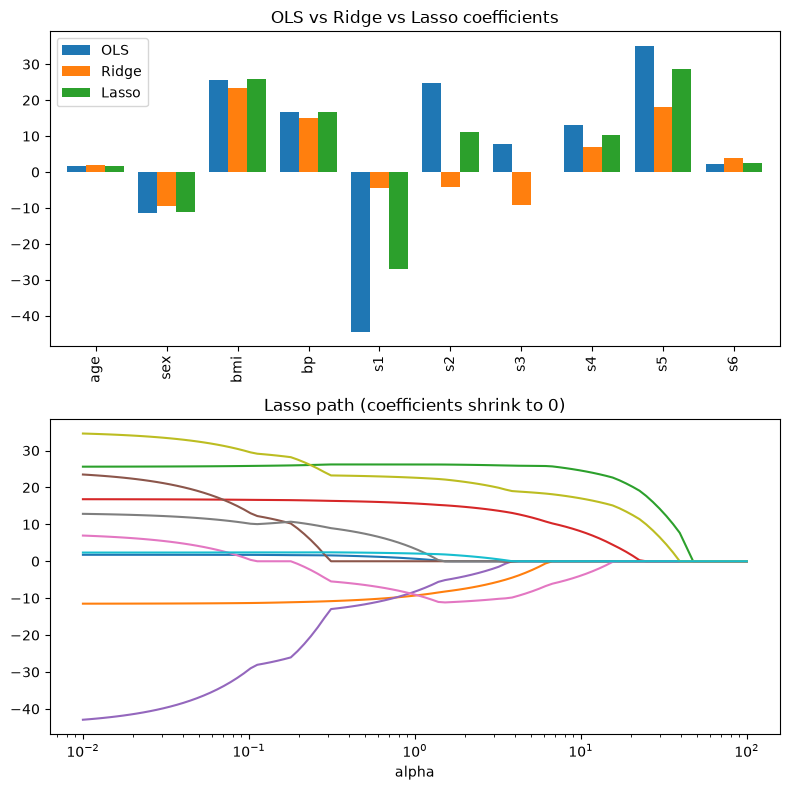

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

df = load_diabetes(as_frame=True).frame
print("Shape:", df.shape, "| Missing values:", int(df.isnull().sum().sum()))
X = df.drop(columns="target"); y = df["target"]

# Multicollinearity: highly correlated feature pairs
corr = X.corr().abs().where(np.triu(np.ones((10, 10)), 1).astype(bool)).stack()
print("Most correlated pairs:\n", corr.sort_values(ascending=False).head(3).round(3).to_string())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
sc = StandardScaler()
X_train = sc.fit_transform(X_train); X_test = sc.transform(X_test)

# alpha values chosen earlier using RidgeCV / LassoCV (10-fold cross-validation)
models = {"OLS": LinearRegression(), "Ridge": Ridge(alpha=53.37), "Lasso": Lasso(alpha=0.1485)}
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    p_tr, p_te = m.predict(X_train), m.predict(X_test)
    rows.append([name, mean_squared_error(y_train, p_tr), mean_squared_error(y_test, p_te),
                 np.sqrt(mean_squared_error(y_test, p_te)), r2_score(y_train, p_tr), r2_score(y_test, p_te)])

print("\n", pd.DataFrame(rows, columns=["Model", "Train MSE", "Test MSE", "Test RMSE", "Train R2", "Test R2"])
      .round(3).to_string(index=False))

coefs = pd.DataFrame({n: m.coef_ for n, m in models.items()}, index=X.columns)
print("\nCoefficients:\n", coefs.round(2).to_string())
print("\nFeatures removed by Lasso:", list(coefs.index[coefs["Lasso"] == 0]))

alphas = np.logspace(-2, 2, 100)
path = np.array([Lasso(alpha=a, max_iter=50000).fit(X_train, y_train).coef_ for a in alphas])

fig, ax = plt.subplots(2, 1, figsize=(8, 8))
coefs.plot(kind="bar", ax=ax[0], width=0.8); ax[0].set_title("OLS vs Ridge vs Lasso coefficients")
ax[1].plot(alphas, path); ax[1].set_xscale("log"); ax[1].set_xlabel("alpha")
ax[1].set_title("Lasso path (coefficients shrink to 0)"); plt.tight_layout()